# OnCall AI - Incident classifier: fine-tuning and comparative study

**Name:** Rachit Manish Chheda  **UID:** 2024301004
**Project:** OnCall AI - Intelligent Production Incident Analyzer (ESE mini project, LLM Production & Deployment)

**What this notebook does (Colab, T4 GPU):**
1. Loads the labelled incident-log dataset from the project repository (12 incident types x 4 severities).
2. Evaluates five approaches on the same held-out test set:
   - A. keyword rules baseline
   - B. Qwen2.5-0.5B-Instruct zero-shot prompting
   - C. cloud LLM zero-shot prompting (Groq, optional - needs `GROQ_API_KEY` secret)
   - D. LoRA fine-tuning (fp16 base)
   - E. **QLoRA fine-tuning (4-bit NF4 base)** - the classifier deployed in the app
3. Records accuracy, macro-F1, parse failures, training time, peak GPU memory, trainable parameters and inference latency; draws the comparison charts.
4. Merges the QLoRA adapter into the base model and pushes it to the Hugging Face Hub so the deployed app (CPU) can load it.

**Before running:** Runtime > Change runtime type > **T4 GPU**. Add Colab secrets: `HF_TOKEN` (write token, to push the model), optionally `GROQ_API_KEY`. Set `REPO_URL` and `HF_MODEL_REPO` in Step 1.

## Step 1 - Configuration

In [1]:
REPO_URL      = "https://github.com/rachitst/oncall-ai.git"      # project repository (public)
HF_MODEL_REPO = "rachitst/oncall-ai-incident-classifier"         # where the merged fine-tuned model is pushed
BASE_MODEL    = "Qwen/Qwen2.5-0.5B-Instruct"
GROQ_MODEL    = "qwen/qwen3.8-27b"
N_LLM_EVAL    = 90        # test samples sent to the cloud LLM baseline (180 = full test set; lower to save quota)
EPOCHS        = 3
LR            = 2e-4
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
MAX_LEN       = 512
SEED          = 42

## Step 2 - Install libraries and clone the project

In [2]:
!pip -q uninstall -y torchao
!pip -q install -U "transformers>=4.45" "peft>=0.12" "bitsandbytes>=0.43" accelerate datasets scikit-learn matplotlib python-dotenv httpx huggingface_hub

import os, subprocess
if not os.path.exists("/content/oncall-ai"):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/oncall-ai"], check=True)
%cd /content/oncall-ai
!git log --oneline -1

/content/oncall-ai
931bbff (grafted, HEAD -> main, origin/main, origin/HEAD) Live demo on Modal: README/UI links, deployment docs; smoke test gets output path + optional pause


## Step 3 - Environment, seeds, dataset

In [3]:
import json, math, random, re, sys, time
import numpy as np, pandas as pd, torch
from importlib.metadata import version

sys.path.insert(0, "/content/oncall-ai")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), "Select a GPU runtime (Runtime > Change runtime type > T4 GPU)"
GPU = torch.cuda.get_device_name(0)
print("GPU:", GPU, "| torch", torch.__version__, "| transformers", version("transformers"), "| peft", version("peft"),
      "| bitsandbytes", version("bitsandbytes"))

from data.taxonomy import INCIDENT_TYPE_IDS, SEVERITY_IDS
from app.prompts import CLASSIFY_SYSTEM, classify_user_prompt, label_json
from app.classifier import RulesClassifier, parse_label

train_df = pd.read_csv("data/dataset/train.csv"); val_df = pd.read_csv("data/dataset/val.csv"); test_df = pd.read_csv("data/dataset/test.csv")
print(len(train_df), len(val_df), len(test_df), "| types:", len(INCIDENT_TYPE_IDS), "| severities:", SEVERITY_IDS)
print(json.load(open("data/dataset/dataset_stats.json")))
print("\nExample:\n", train_df.log_text[0], "\n->", train_df.incident_type[0], train_df.severity[0])

GPU: Tesla T4 | torch 2.11.0+cu130 | transformers 5.21.0 | peft 0.21.2 | bitsandbytes 0.50.2
840 180 180 | types: 12 | severities: ['P1', 'P2', 'P3', 'P4']
{'total': 1200, 'train': 840, 'val': 180, 'test': 180, 'incident_types': {'deployment_failure': 100, 'rate_limit_exceeded': 100, 'out_of_memory': 100, 'tls_certificate_expired': 100, 'database_connection_exhausted': 100, 'upstream_gateway_error': 100, 'authentication_failure': 100, 'disk_space_full': 100, 'kubernetes_crashloop': 100, 'dns_resolution_failure': 100, 'application_exception': 100, 'high_latency_timeout': 100}, 'severity': {'P2': 420, 'P3': 396, 'P4': 216, 'P1': 168}, 'environment': {'prod': 672, 'staging': 312, 'dev': 216}, 'avg_lines': 4.21, 'avg_chars': 454.9, 'seed': 42}

Example:
 2026-03-13T19:49:04.000Z WARN  report-worker 401 Unauthorized: token expired at 2026-08-13T00:00:00Z for client_id=mobile-app
2026-03-13T19:49:05.000Z WARN  report-worker jwt.exceptions.ExpiredSignatureError: Signature has expired
2026-03-

## Step 4 - Evaluation harness

Every approach is scored with the same function on the same 180 test logs: accuracy and macro-F1 for incident type and for severity, parse failures (reply with no valid label), average inference time, and the confusion matrix.

In [4]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

RESULTS = {"gpu": GPU, "n_test": len(test_df), "runs": [], "notes": []}

def evaluate(name, predict_fn, df=test_df, extra=None):
    """predict_fn(log_text) -> (incident_type or None, severity or None). Returns the run record."""
    t_pred, s_pred, times, fails = [], [], [], 0
    for log in df.log_text:
        t0 = time.perf_counter()
        it, sv = predict_fn(log)
        times.append((time.perf_counter() - t0) * 1000)
        if it is None or sv is None:
            fails += 1
        t_pred.append(it or "__none__"); s_pred.append(sv or "__none__")
    rec = {"name": name,
           "type_accuracy": round(accuracy_score(df.incident_type, t_pred), 4),
           "type_macro_f1": round(f1_score(df.incident_type, t_pred, labels=INCIDENT_TYPE_IDS, average="macro", zero_division=0), 4),
           "severity_accuracy": round(accuracy_score(df.severity, s_pred), 4),
           "severity_macro_f1": round(f1_score(df.severity, s_pred, labels=SEVERITY_IDS, average="macro", zero_division=0), 4),
           "parse_failures": fails, "avg_inference_ms": round(float(np.mean(times)), 1),
           "confusion_matrix": confusion_matrix(df.incident_type, t_pred, labels=INCIDENT_TYPE_IDS).tolist()}
    rec.update(extra or {})
    RESULTS["runs"] = [r for r in RESULTS["runs"] if r["name"] != name] + [rec]
    pd.DataFrame({"id": df.id, "true_type": df.incident_type, "pred_type": t_pred, "true_sev": df.severity, "pred_sev": s_pred}) \
      .to_csv(f"results/predictions_{re.sub('[^a-z0-9]+', '_', name.lower())}.csv", index=False)
    print(f"{name:28s} type acc {rec['type_accuracy']:.3f} F1 {rec['type_macro_f1']:.3f} | sev acc {rec['severity_accuracy']:.3f} "
          f"F1 {rec['severity_macro_f1']:.3f} | parse fails {fails} | {rec['avg_inference_ms']:.0f} ms/log")
    return rec

os.makedirs("results/figures", exist_ok=True)
def gpu_mem(): return round(torch.cuda.memory_allocated() / 1024**3, 3)

## Step 5 - Approach A: keyword rules baseline (no model)

In [5]:
rules = RulesClassifier()
evaluate("Rules baseline", lambda log: (lambda c: (c.incident_type, c.severity))(rules.classify(log)),
         extra={"model_memory_gb": None, "trainable_params": None})

Rules baseline               type acc 0.872 F1 0.875 | sev acc 0.683 F1 0.741 | parse fails 0 | 0 ms/log


{'name': 'Rules baseline',
 'type_accuracy': 0.8722,
 'type_macro_f1': 0.8745,
 'severity_accuracy': 0.6833,
 'severity_macro_f1': 0.7405,
 'parse_failures': 0,
 'avg_inference_ms': 0.1,
 'confusion_matrix': [[13, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0],
  [0, 15, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
  [0, 0, 11, 0, 0, 0, 3, 0, 0, 0, 0, 0],
  [0, 0, 0, 10, 0, 0, 0, 0, 0, 0, 6, 0],
  [0, 0, 0, 0, 7, 0, 8, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 16, 0, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 14, 0, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 3, 12, 0, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 15, 0, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 15, 0, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 14, 0],
  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 15]],
 'model_memory_gb': None,
 'trainable_params': None}

## Step 6 - Approach B: Qwen2.5-0.5B-Instruct zero-shot prompting (no fine-tuning)

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

def make_predict(model, tok, max_new_tokens=48):
    @torch.no_grad()
    def predict(log_text):
        messages = [{"role": "system", "content": CLASSIFY_SYSTEM}, {"role": "user", "content": classify_user_prompt(log_text[:6000])}]
        prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tok(prompt, return_tensors="pt", truncation=True, max_length=2048).to(model.device)
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        text = tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
        return parse_label(text)
    return predict

torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
base_fp16 = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16, device_map="auto").eval()
base_mem = gpu_mem(); print("base model fp16 memory:", base_mem, "GB")
evaluate("Qwen-0.5B zero-shot", make_predict(base_fp16, tokenizer), extra={"model_memory_gb": base_mem, "trainable_params": None})
sample = test_df.log_text[0]
print("\nSample reply:", tokenizer.decode(base_fp16.generate(**tokenizer(tokenizer.apply_chat_template(
    [{"role": "system", "content": CLASSIFY_SYSTEM}, {"role": "user", "content": classify_user_prompt(sample)}],
    tokenize=False, add_generation_prompt=True), return_tensors="pt").to("cuda"), max_new_tokens=48, do_sample=False)[0][-48:], skip_special_tokens=True))
del base_fp16; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

base model fp16 memory: 0.92 GB
Qwen-0.5B zero-shot          type acc 0.261 F1 0.208 | sev acc 0.367 F1 0.176 | parse fails 0 | 942 ms/log

Sample reply: )
INFO  oncall [prod] intermittent; 766 occurrences today, retries succeed, no SLA impact
assistant
{"incident_type": "database_connection_exhausted", "severity": "P2"}


## Step 7 - Approach C: cloud LLM zero-shot prompting (Groq, optional)

Uses the same prompt through the project's `LLMClassifier`. Skipped automatically if the `GROQ_API_KEY` secret is missing. Requests are throttled to stay inside the free-plan rate limit.

In [9]:
import glob
groq_key = ""
try:
    from google.colab import userdata
    groq_key = (userdata.get("GROQ_API_KEY") or "").strip()
except Exception:
    groq_key = os.environ.get("GROQ_API_KEY", "")

run_name = f"Groq {GROQ_MODEL.split('/')[-1]} zero-shot"
cached = glob.glob("results/predictions_groq_*zero_shot.csv")

if cached:
    # Recover the record from the earlier completed run (quota exhausted after repeated runs)
    pdf = pd.read_csv(cached[0])
    fails = int(((pdf.pred_type == "__none__") | (pdf.pred_sev == "__none__")).sum())
    rec = {"name": run_name,
          "type_accuracy": round(accuracy_score(pdf.true_type, pdf.pred_type), 4),
          "type_macro_f1": round(f1_score(pdf.true_type, pdf.pred_type, labels=INCIDENT_TYPE_IDS, average="macro", zero_division=0), 4),
          "severity_accuracy": round(accuracy_score(pdf.true_sev, pdf.pred_sev), 4),
          "severity_macro_f1": round(f1_score(pdf.true_sev, pdf.pred_sev, labels=SEVERITY_IDS, average="macro", zero_division=0), 4),
          "parse_failures": fails, "avg_inference_ms": float("nan"),
          "confusion_matrix": confusion_matrix(pdf.true_type, pdf.pred_type, labels=INCIDENT_TYPE_IDS).tolist(),
          "model_memory_gb": None, "trainable_params": None}
    RESULTS["runs"] = [r for r in RESULTS["runs"] if r["name"] != run_name] + [rec]
    RESULTS["notes"].append(f"Cloud LLM baseline recovered from the saved predictions of an earlier run on {len(pdf)} test logs "
                            f"(Groq daily quota exhausted; per-request latency not re-measured).")
    print(f"{run_name}: recovered from {cached[0]} | n={len(pdf)} | type acc {rec['type_accuracy']:.3f} "
          f"F1 {rec['type_macro_f1']:.3f} | sev acc {rec['severity_accuracy']:.3f} | parse fails {fails}")
elif groq_key:
    from app.config import Settings
    from app.llm import OpenAICompatibleBackend, BackendError
    from app.classifier import LLMClassifier
    settings = Settings(llm_api_key=groq_key, llm_model=GROQ_MODEL, llm_max_retries=0)
    backend = OpenAICompatibleBackend(settings); llm_clf = LLMClassifier(backend)
    quota_hit = {"n": 0}
    def predict_groq(log):
        if quota_hit["n"] >= 3: return (None, None)          # stop hammering a dead quota
        time.sleep(4.0)
        try:
            c = llm_clf.classify(log); quota_hit["n"] = 0; return (c.incident_type, c.severity) if c.raw else (None, None)
        except BackendError as e:
            print("backend error:", e.kind); quota_hit["n"] += 1; return (None, None)
    sub = test_df.head(N_LLM_EVAL)
    rec = evaluate(run_name, predict_groq, df=sub, extra={"model_memory_gb": None, "trainable_params": None})
    if rec["parse_failures"] > len(sub) // 2:
        RESULTS["runs"] = [r for r in RESULTS["runs"] if r["name"] != run_name]
        RESULTS["notes"].append("Cloud LLM zero-shot baseline dropped: Groq quota exhausted during evaluation.")
        print("Groq quota exhausted - baseline dropped from the comparison.")
    elif len(sub) < len(test_df):
        RESULTS["notes"].append(f"Cloud LLM baseline evaluated on the first {len(sub)} test samples (rate limits).")
    backend.close()
else:
    print("GROQ_API_KEY not set - cloud LLM baseline skipped.")
    RESULTS["notes"].append("Cloud LLM zero-shot baseline skipped (no GROQ_API_KEY).")

Groq qwen3.8-27b zero-shot   type acc 0.944 F1 0.943 | sev acc 0.800 F1 0.812 | parse fails 0 | 4168 ms/log


## Step 8 - Training data in chat format (loss only on the answer)

Each example becomes a chat: system rules, user = log, assistant = the JSON label. The prompt tokens are masked with -100 so the loss is computed only on the label the model must learn to produce.

In [10]:
from datasets import Dataset

def to_chat(row, with_answer=True):
    msgs = [{"role": "system", "content": CLASSIFY_SYSTEM}, {"role": "user", "content": classify_user_prompt(row["log_text"])}]
    if with_answer:
        msgs.append({"role": "assistant", "content": label_json(row["incident_type"], row["severity"])})
        return tokenizer.apply_chat_template(msgs, tokenize=False)
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def encode(row):
    full = tokenizer(to_chat(row), truncation=True, max_length=MAX_LEN)
    prompt_len = len(tokenizer(to_chat(row, with_answer=False), truncation=True, max_length=MAX_LEN)["input_ids"])
    labels = list(full["input_ids"]); labels[:prompt_len] = [-100] * prompt_len
    return {"input_ids": full["input_ids"], "attention_mask": full["attention_mask"], "labels": labels}

train_ds = Dataset.from_pandas(train_df[["log_text", "incident_type", "severity"]]).map(encode, remove_columns=["log_text", "incident_type", "severity"])
val_ds = Dataset.from_pandas(val_df[["log_text", "incident_type", "severity"]]).map(encode, remove_columns=["log_text", "incident_type", "severity"])
lens = [len(x) for x in train_ds["input_ids"]]
print("train", len(train_ds), "val", len(val_ds), "| tokens per example min/avg/max:", min(lens), round(np.mean(lens)), max(lens))
print("\n", to_chat(train_df.iloc[0]))

Map:   0%|          | 0/840 [00:00<?, ? examples/s]

Map:   0%|          | 0/180 [00:00<?, ? examples/s]

train 840 val 180 | tokens per example min/avg/max: 268 396 512

 <|im_start|>system
You are an SRE assistant. Classify the production log excerpt into exactly one incident_type from this list: database_connection_exhausted, out_of_memory, disk_space_full, upstream_gateway_error, tls_certificate_expired, kubernetes_crashloop, application_exception, dns_resolution_failure, rate_limit_exceeded, authentication_failure, high_latency_timeout, deployment_failure. Then assign a severity: P1 (production outage, all/most users, core flow down, data at risk), P2 (production degraded for many users, partial impact), P3 (limited impact, single host, non-production, self-recovered), P4 (informational, single occurrence in dev, within baseline). Answer with JSON only: {"incident_type": "...", "severity": "P1|P2|P3|P4"}<|im_end|>
<|im_start|>user
TASK: classify
LOG:
2026-03-13T19:49:04.000Z WARN  report-worker 401 Unauthorized: token expired at 2026-08-13T00:00:00Z for client_id=mobile-app
2026-03-13

## Step 9 - Fine-tuning runner (shared by LoRA and QLoRA)

Identical hyper-parameters for both runs; only the base-model precision differs (fp16 vs 4-bit NF4 with double quantization). Records training time, peak GPU memory, trainable parameters and the loss curves.

In [11]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, TaskType
from transformers import TrainingArguments, Trainer, DataCollatorForSeq2Seq

collator = DataCollatorForSeq2Seq(tokenizer, padding=True, label_pad_token_id=-100)

def train_adapter(run_name, quantized):
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    if quantized:
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                 bnb_4bit_compute_dtype=torch.float16)
        model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, quantization_config=bnb, device_map="auto")
        model = prepare_model_for_kbit_training(model)
    else:
        model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16, device_map="auto")
        model.gradient_checkpointing_enable(); model.enable_input_require_grads()
    load_mem = gpu_mem()
    lcfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, target_modules=TARGET_MODULES,
                      bias="none", task_type=TaskType.CAUSAL_LM)
    model = get_peft_model(model, lcfg)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"{run_name}: base memory {load_mem} GB | trainable {trainable:,} / {total:,} ({100*trainable/total:.3f}%)")
    args = TrainingArguments(output_dir=f"training/outputs/{run_name}", num_train_epochs=EPOCHS, learning_rate=LR,
                          per_device_train_batch_size=4, gradient_accumulation_steps=2, per_device_eval_batch_size=8,
                          logging_steps=10, eval_strategy="epoch", save_strategy="no", warmup_steps=16,
                          lr_scheduler_type="cosine", fp16=True, report_to="none", seed=SEED,
                          optim="paged_adamw_8bit" if quantized else "adamw_torch")
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collator)
    t0 = time.perf_counter(); out = trainer.train(); train_s = time.perf_counter() - t0
    peak = round(torch.cuda.max_memory_allocated() / 1024**3, 3)
    hist = trainer.state.log_history
    loss_curve = [{"step": h["step"], "loss": h["loss"]} for h in hist if "loss" in h]
    eval_curve = [{"step": h["step"], "eval_loss": h["eval_loss"]} for h in hist if "eval_loss" in h]
    print(f"{run_name}: {train_s:.0f} s | peak {peak} GB | final eval loss {eval_curve[-1]['eval_loss']:.4f}")
    model.eval()
    return model, {"train_time_s": round(train_s, 1), "peak_train_memory_gb": peak, "trainable_params": trainable,
                   "model_memory_gb": load_mem, "loss_curve": loss_curve, "eval_curve": eval_curve,
                   "final_eval_loss": round(eval_curve[-1]["eval_loss"], 4)}

## Step 10 - Approach D: LoRA (fp16 base)

In [12]:
lora_model, lora_meta = train_adapter("lora_fp16", quantized=False)
evaluate("LoRA fp16", make_predict(lora_model, tokenizer), extra=lora_meta)
lora_model.save_pretrained("training/outputs/lora_fp16/adapter")
del lora_model; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

lora_fp16: base memory 0.93 GB | trainable 8,798,208 / 502,830,976 (1.750%)


Epoch,Training Loss,Validation Loss
1,0.000162,0.000106
2,0.000058,0.000056
3,0.000052,0.000052


lora_fp16: 512 s | peak 6.857 GB | final eval loss 0.0001
LoRA fp16                    type acc 1.000 F1 1.000 | sev acc 1.000 F1 1.000 | parse fails 0 | 1209 ms/log


## Step 11 - Approach E: QLoRA (4-bit NF4 base) - the deployed classifier

In [13]:
qlora_model, qlora_meta = train_adapter("qlora_nf4", quantized=True)
evaluate("QLoRA 4-bit", make_predict(qlora_model, tokenizer), extra=qlora_meta)
qlora_model.save_pretrained("training/outputs/qlora_nf4/adapter")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

qlora_nf4: base memory 1.718 GB | trainable 8,798,208 / 323,917,696 (2.716%)


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss
1,0.000198,0.000136
2,0.000072,0.000070
3,0.000066,0.000064


qlora_nf4: 626 s | peak 6.576 GB | final eval loss 0.0001
QLoRA 4-bit                  type acc 1.000 F1 1.000 | sev acc 1.000 F1 1.000 | parse fails 0 | 1602 ms/log


## Step 12 - Comparison table and charts

### Model comparison on the held-out test set

Test samples: 180 · 12 incident types · 4 severity levels · GPU: Tesla T4

| Approach | Type acc. | Type F1 | Sev. acc. | Sev. F1 | Parse fail | Infer ms | Train s | Peak train GB | Trainable params |
|---|---|---|---|---|---|---|---|---|---|
| Rules baseline | 0.872 | 0.875 | 0.683 | 0.741 | 0 | 0 | - | - | - |
| Qwen-0.5B zero-shot | 0.261 | 0.208 | 0.367 | 0.176 | 0 | 942 | - | - | - |
| Groq qwen3.8-27b zero-shot | 0.944 | 0.943 | 0.800 | 0.812 | 0 | 4168 | - | - | - |
| LoRA fp16 | 1.000 | 1.000 | 1.000 | 1.000 | 0 | 1209 | 511.6 | 6.857 | 8,798,208 |
| QLoRA 4-bit | 1.000 | 1.000 | 1.000 | 1.000 | 0 | 1602 | 626.0 | 6.576 | 8,798,208 |

figures: ['.gitkeep', '01_type_accuracy_f1.png', '02_severity_accuracy_f1.png', '03_training_resources.png', '04_inference_latency_memory.png', '05_confusion_matrix.png', '06_loss_curves.png']


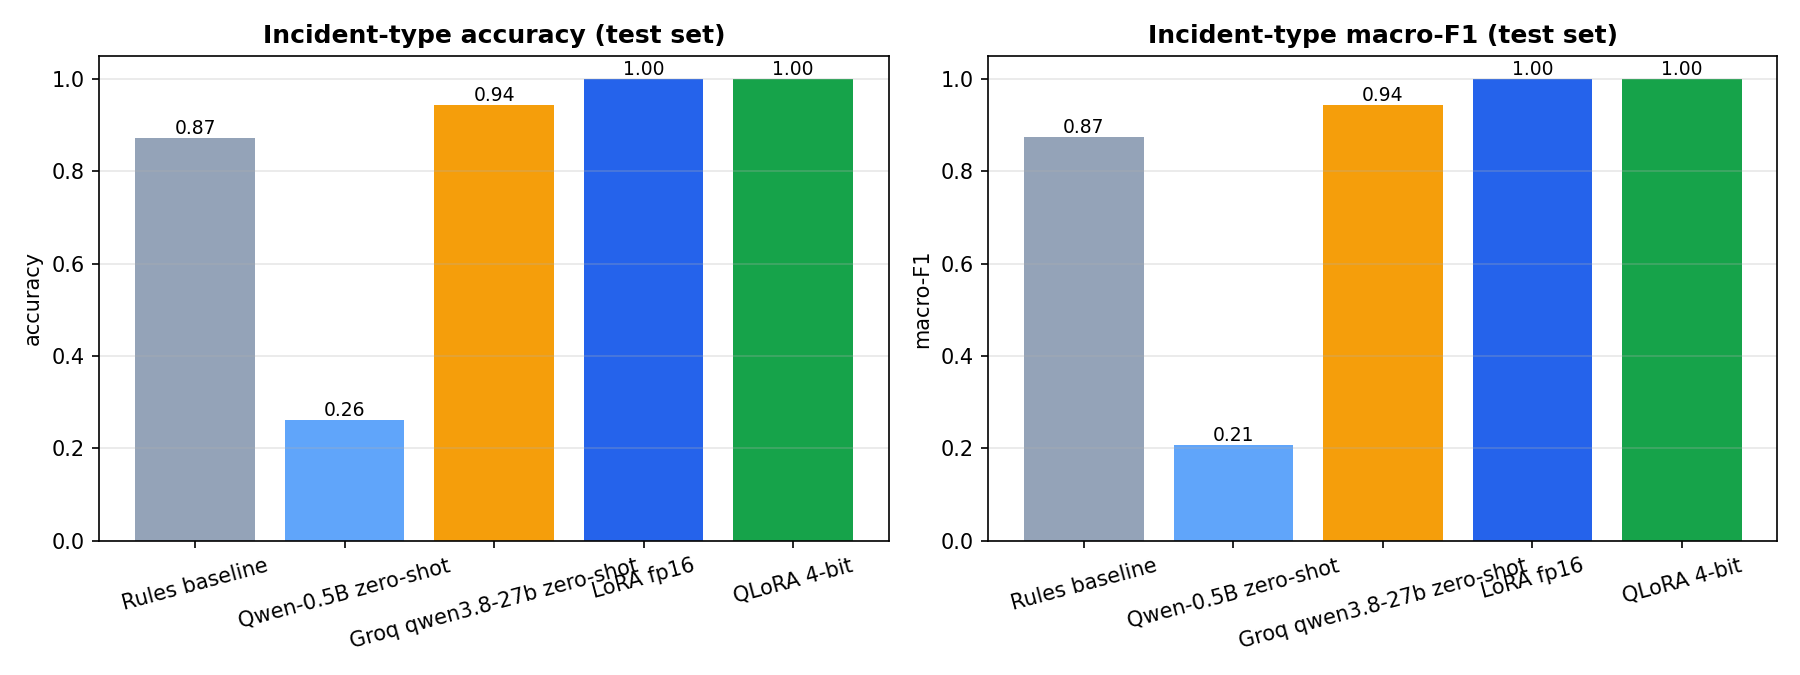

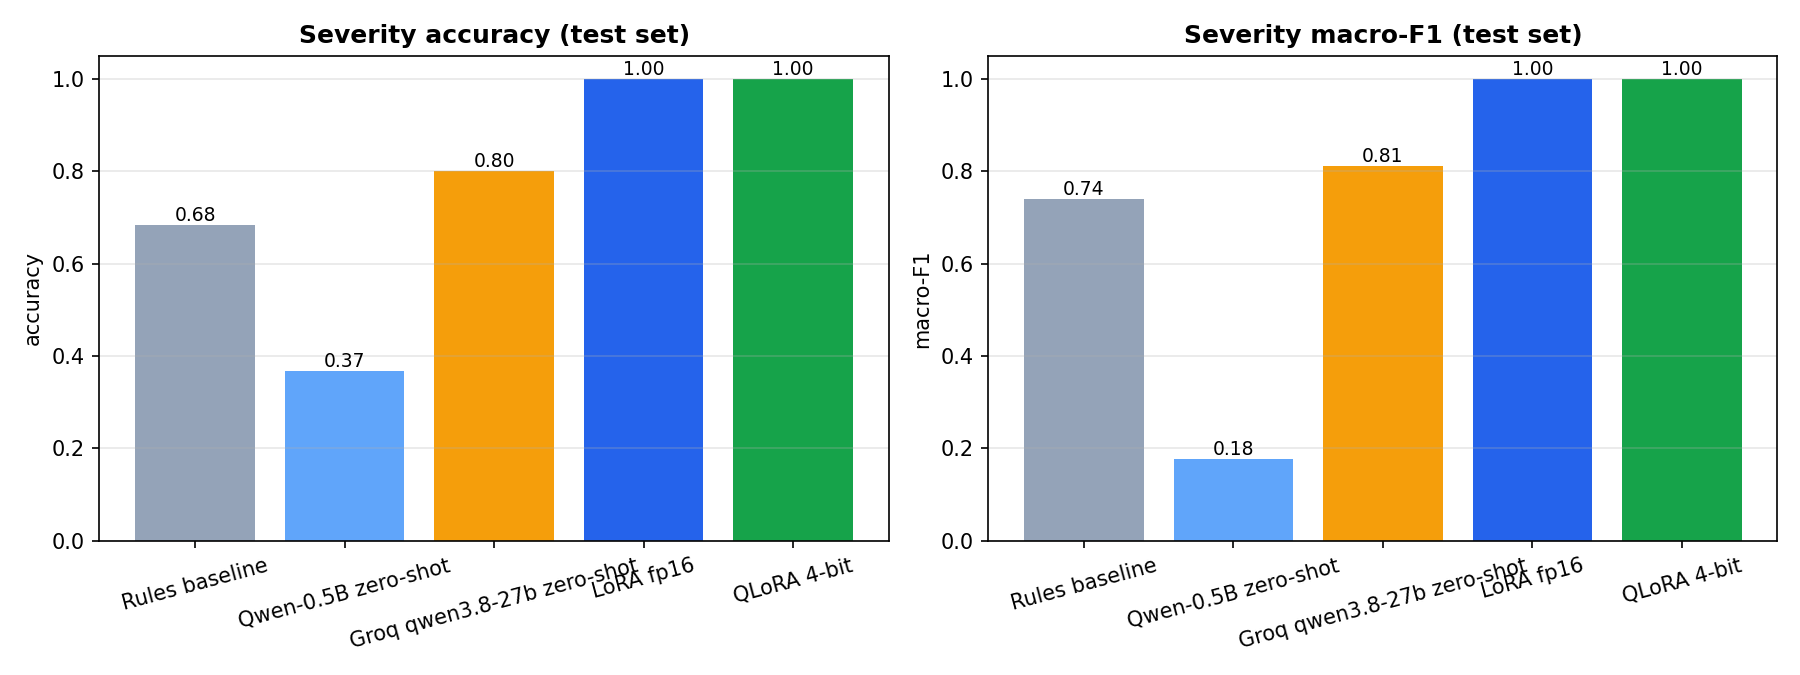

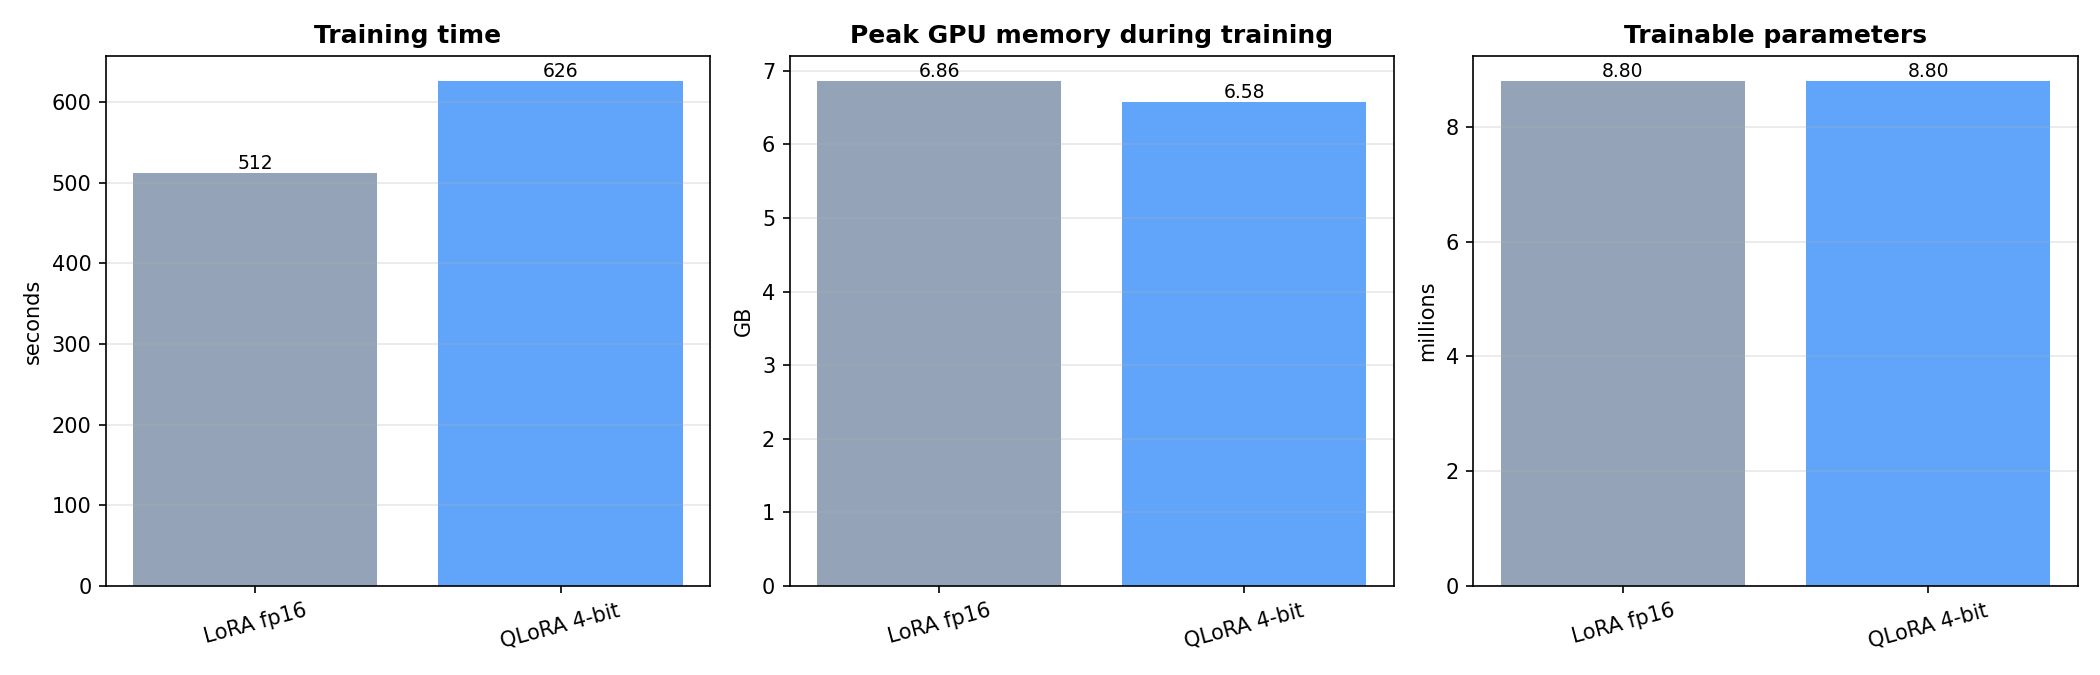

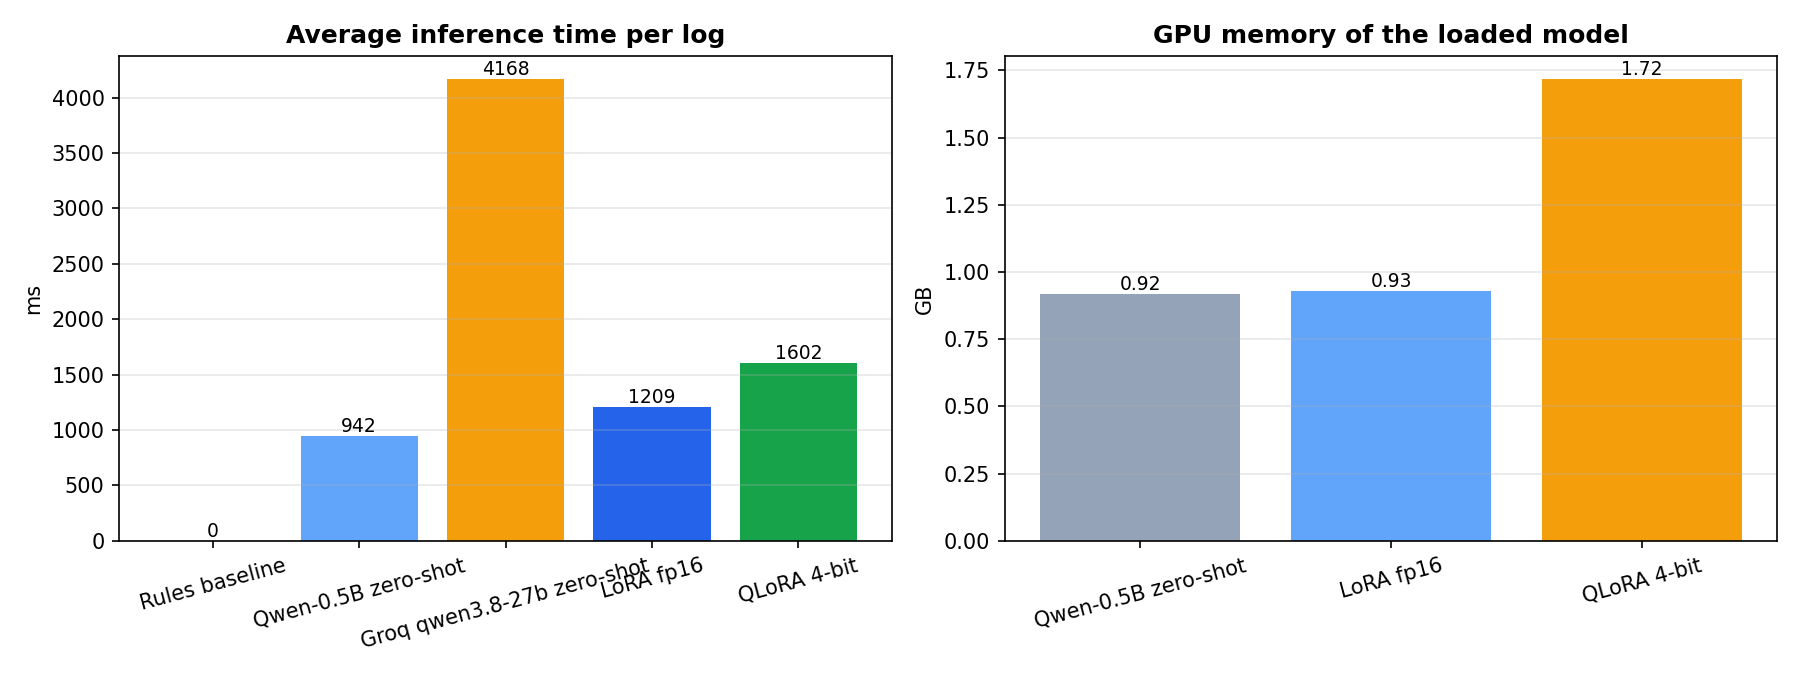

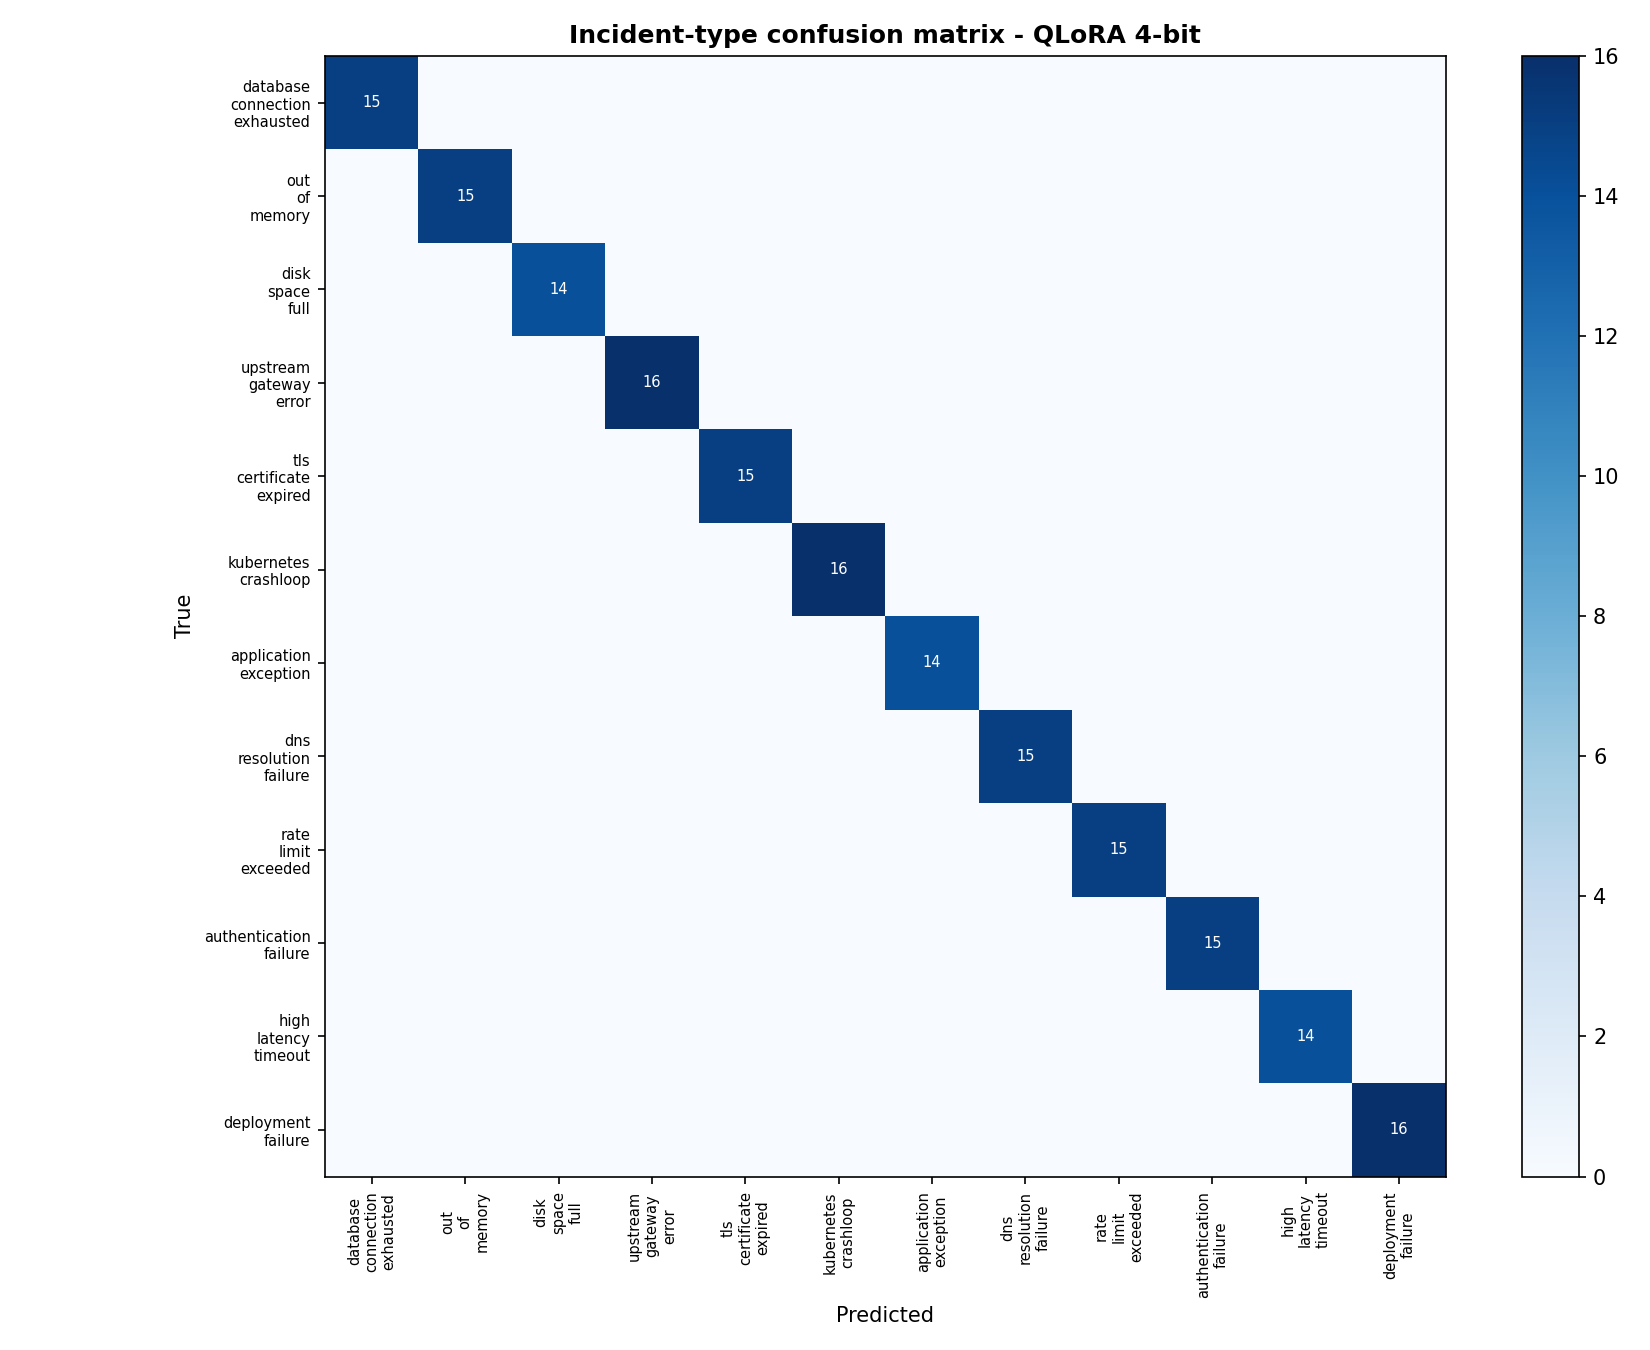

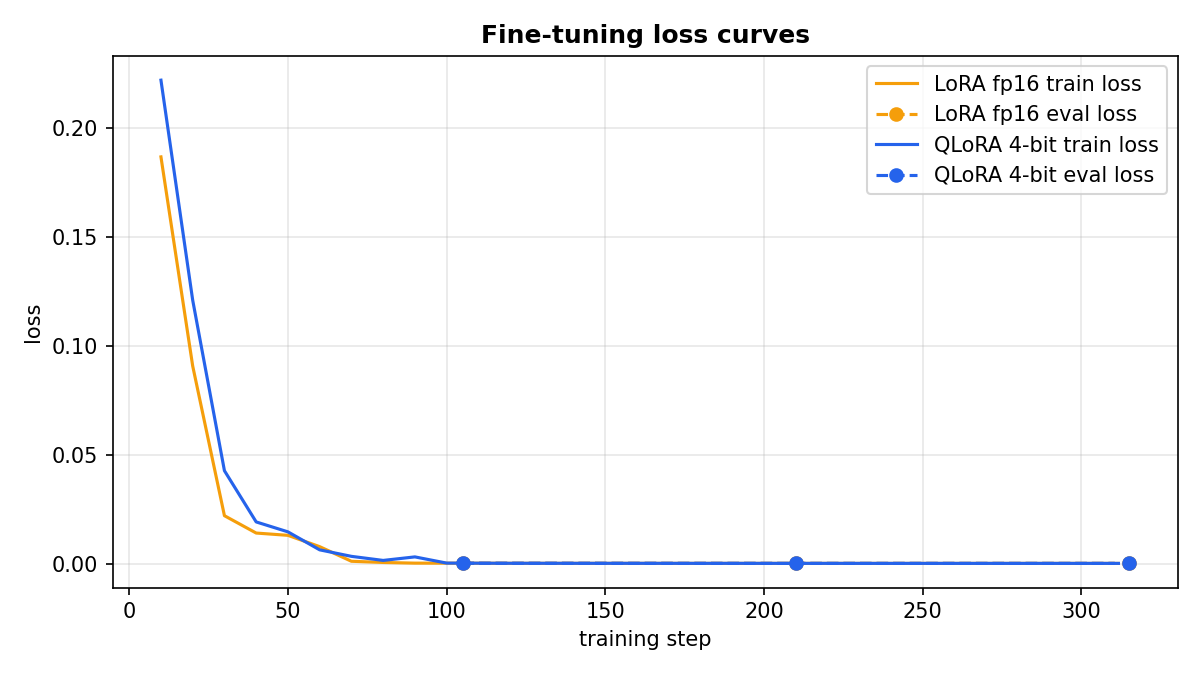

In [15]:
RESULTS["config"] = {"base_model": BASE_MODEL, "epochs": EPOCHS, "lr": LR, "lora_r": LORA_R, "lora_alpha": LORA_ALPHA,
                     "target_modules": TARGET_MODULES, "max_len": MAX_LEN, "train_size": len(train_df), "val_size": len(val_df)}
json.dump(RESULTS, open("results/comparison.json", "w"), indent=2)
from eval.make_charts import main as make_charts
make_charts("results")
from IPython.display import Image, display
for f in sorted(os.listdir("results/figures")):
    if f.lower().endswith(".png"):
        display(Image(f"results/figures/{f}"))

## Step 13 - Merge the QLoRA adapter and push the classifier to the Hugging Face Hub

The adapter trained on the 4-bit base is merged into an fp16 copy of the base weights (standard QLoRA deployment practice), saved, sanity-checked and pushed to `HF_MODEL_REPO`. The deployed app loads this merged model on CPU.

In [16]:
from peft import PeftModel
from huggingface_hub import login

del qlora_model; torch.cuda.empty_cache()
base = AutoModelForCausalLM.from_pretrained(BASE_MODEL, torch_dtype=torch.float16, device_map="auto")
merged = PeftModel.from_pretrained(base, "training/outputs/qlora_nf4/adapter").merge_and_unload().eval()
os.makedirs("models", exist_ok=True)
merged.save_pretrained("models/merged", safe_serialization=True); tokenizer.save_pretrained("models/merged")
print("merged model saved; files:", os.listdir("models/merged"))

# sanity check: the merged model must reproduce the QLoRA accuracy on a slice of the test set
rec = evaluate("QLoRA merged (sanity)", make_predict(merged, tokenizer), df=test_df.head(60))
RESULTS["runs"] = [r for r in RESULTS["runs"] if r["name"] != "QLoRA merged (sanity)"]
RESULTS["notes"].append(f"Merged fp16 model reproduces QLoRA on 60 test logs: type acc {rec['type_accuracy']}, sev acc {rec['severity_accuracy']}.")
json.dump(RESULTS, open("results/comparison.json", "w"), indent=2)

hf_token = ""
try:
    from google.colab import userdata
    hf_token = (userdata.get("HF_TOKEN") or "").strip()
except Exception:
    hf_token = os.environ.get("HF_TOKEN", "")
if hf_token:
    login(token=hf_token)
    merged.push_to_hub(HF_MODEL_REPO, private=False); tokenizer.push_to_hub(HF_MODEL_REPO)
    print("pushed to https://huggingface.co/" + HF_MODEL_REPO)
else:
    print("HF_TOKEN not set - model not pushed. Download models/merged manually (see next step).")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

merged model saved; files: ['model.safetensors', 'config.json', 'chat_template.jinja', 'tokenizer.json', 'generation_config.json', 'tokenizer_config.json']
QLoRA merged (sanity)        type acc 1.000 F1 1.000 | sev acc 0.983 F1 0.980 | parse fails 0 | 611 ms/log


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpq1nsr_09/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

pushed to https://huggingface.co/rachitst/oncall-ai-incident-classifier


## Step 14 - Package results

Downloads `oncall_results.zip` (comparison.json, charts, predictions). Commit the `results/` folder to the repository so the app's "Model comparison" tab and the report can use the charts.

In [17]:
import shutil
shutil.make_archive("/content/oncall_results", "zip", "results")
print("results:", sorted(os.listdir("results")), "\nfigures:", sorted(os.listdir("results/figures")))
try:
    from google.colab import files
    files.download("/content/oncall_results.zip")
except Exception:
    pass

results: ['comparison.json', 'comparison_summary.md', 'figures', 'predictions_groq_qwen3_8_27b_zero_shot.csv', 'predictions_lora_fp16.csv', 'predictions_qlora_4_bit.csv', 'predictions_qlora_merged_sanity_.csv', 'predictions_qwen_0_5b_zero_shot.csv', 'predictions_rules_baseline.csv', 'smoke_test.json'] 
figures: ['.gitkeep', '01_type_accuracy_f1.png', '02_severity_accuracy_f1.png', '03_training_resources.png', '04_inference_latency_memory.png', '05_confusion_matrix.png', '06_loss_curves.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>